# Group Homework 4: GoMart store archetypes
Data Visualization, UEH, Session 4. Team notebook of Team 10.

| | |
|---|---|
| **Team** | Team 10 |
| **Members** | Nguyễn Hoàng Minh (leader), Phạm Quang Minh, Phạm Tuấn Anh, Trần Nhã Đoan, Nguyễn Minh Nguyệt, Trần Nguyễn Thanh Thảo |
| **Status** | Formative homework with written feedback. Task 0 is the first version of Module M6 of our final project. |
| **File** | `GH4_Team10.ipynb` |

All data in this notebook is simulated. It is not real company data.

## Memo to the operations director

**Big Idea:** The 32 evening large-basket stores take 23% of GoMart's orders but make 41% of its late deliveries, so on-time work should start there.

- Type C (evening large-basket grocery): test extra evening riders in a few stores and keep them if on-time delivery improves.
- Type A (high-volume discount small basket): test fewer promotions in a few stores and watch orders and baskets.
- Type B (daytime digital grab-and-go): keep the current setup as the model for daytime service.
- Type D (loyal premium fast-delivery): protect fast delivery and track repeat customers monthly.
- Type E (slow-delivery low-traffic promo): review delivery routes. Its many promotions and few repeat customers do not prove that one causes the other.

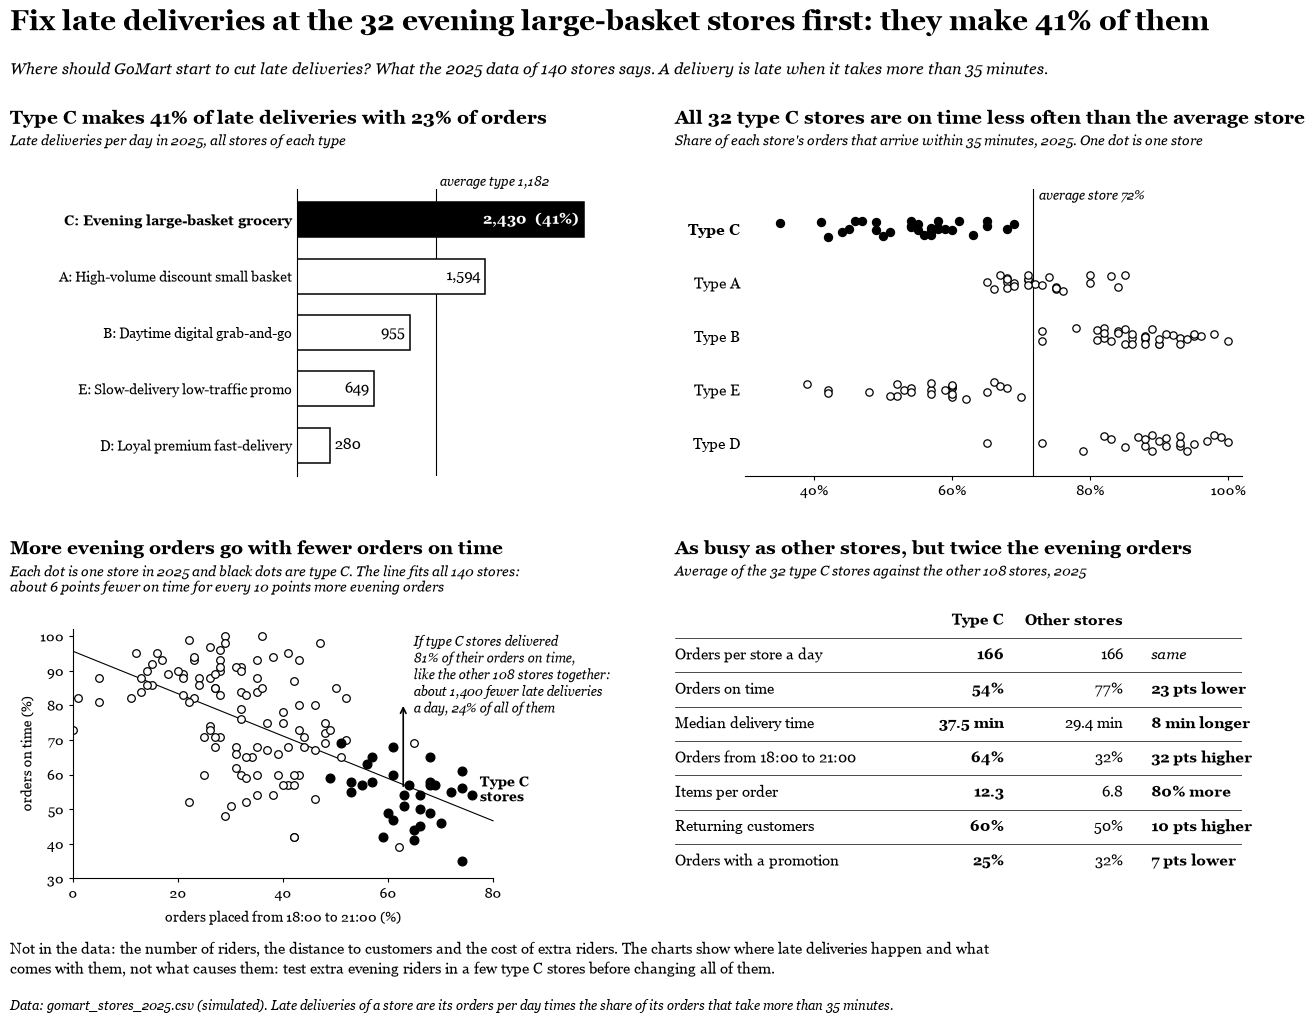

In [1]:
# Task 6: the explanatory chart for the director. Task 6 below draws the same chart again from the Task 4 clusters.
# This cell runs before Setup, so it loads the data and repeats the Task 4 clustering by itself:
# standardize, k-means with k = 5, n_init = 10 and random_state = 0, then letters A to E by orders_per_day (A is the highest).
# The layout follows the decision sheet of our week 1 work: four panels, each answers its own question with the chart
# type that fits it, type C is solid black and the other types are drawn in outline.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

TYPE_NAMES = {
    "A": "High-volume discount small basket",
    "B": "Daytime digital grab-and-go",
    "C": "Evening large-basket grocery",
    "D": "Loyal premium fast-delivery",
    "E": "Slow-delivery low-traffic promo",
}
INK, PAPER = "#000000", "#ffffff"   # the only two colours of the sheet
# The first serif font that this computer has: Georgia on a laptop, usually Liberation Serif on Colab
INSTALLED = {font.name for font in font_manager.fontManager.ttflist}
SERIF = [name for name in ["Georgia", "Times New Roman", "Liberation Serif", "DejaVu Serif"] if name in INSTALLED]
SHEET_STYLE = {                     # used inside rc_context only, so the other charts keep their own style
    "font.family": SERIF,
    "text.color": INK, "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
}


def store_type_table(stores):
    """Orders, late deliveries and evening orders per day for each store type, with their shares in %.

    A delivery is late when it takes more than 35 minutes, so the late deliveries of a store are
    orders_per_day * (1 - ontime_share / 100). The evening orders are the orders placed from 18:00 to 21:00.
    """
    s = stores.assign(late_per_day=stores["orders_per_day"] * (1 - stores["ontime_share"] / 100),
                      evening_per_day=stores["orders_per_day"] * stores["evening_share"] / 100)
    t = s.groupby("cluster").agg(stores=("store_id", "size"),
                                 orders_per_day=("orders_per_day", "sum"),
                                 late_per_day=("late_per_day", "sum"),
                                 evening_per_day=("evening_per_day", "sum"))
    t["orders_%"] = 100 * t["orders_per_day"] / t["orders_per_day"].sum()
    t["late_%"] = 100 * t["late_per_day"] / t["late_per_day"].sum()
    t["late_rate_%"] = 100 * t["late_per_day"] / t["orders_per_day"]
    t["evening_rate_%"] = 100 * t["evening_per_day"] / t["orders_per_day"]
    return t.sort_values("late_%", ascending=False)


def plot_one_page(stores, focus="C"):
    """Four answers for the director: where the late deliveries are, whether every store of the type is late,
    what goes with late delivery (plus a what-if), and how the type differs from the other stores."""
    t = store_type_table(stores)
    s = stores.assign(late_per_day=stores["orders_per_day"] * (1 - stores["ontime_share"] / 100))
    f, rest = s[s["cluster"] == focus], s[s["cluster"] != focus]
    focus_ontime = 100 * (1 - f["late_per_day"].sum() / f["orders_per_day"].sum())        # weighted by orders
    rest_ontime = 100 * (1 - rest["late_per_day"].sum() / rest["orders_per_day"].sum())
    focus_evening = (f["orders_per_day"] * f["evening_share"]).sum() / f["orders_per_day"].sum()
    saved = f["late_per_day"].sum() - f["orders_per_day"].sum() * (1 - rest_ontime / 100)  # the what-if
    avg_store = s["ontime_share"].mean()

    with plt.rc_context(SHEET_STYLE):
        fig = plt.figure(figsize=(14, 10.6), facecolor=PAPER)
        LEFT, RIGHT, TOP_Y, LOW_Y = 0.06, 0.535, 0.853, 0.447   # where the panel titles start
        bar_ax = fig.add_axes([0.265, 0.525, 0.215, 0.27])
        strip_ax = fig.add_axes([0.585, 0.525, 0.355, 0.27])
        dot_ax = fig.add_axes([0.105, 0.145, 0.375, 0.235])
        card_ax = fig.add_axes([RIGHT, 0.145, 0.405, 0.255])

        def panel_title(x, y, title, note):
            fig.text(x, y, title, ha="left", va="bottom", fontsize=13.5, fontweight="bold")
            fig.text(x, y - 0.006, note, ha="left", va="top", fontsize=10, style="italic")

        # 1. Where the late deliveries are: late deliveries per day of each type, with the average type as a line
        order = t.sort_values("late_per_day")                     # the largest bar goes to the top
        for y, (c, row) in enumerate(order.iterrows()):
            hi = c == focus
            bar_ax.barh(y, row["late_per_day"], height=0.62, color=INK if hi else PAPER, edgecolor=INK, linewidth=1.1)
            label = f"{row['late_per_day']:,.0f}" + (f"  ({row['late_%']:.0f}%)" if hi else "")
            inside = row["late_per_day"] > 500                    # small bars get their number outside
            bar_ax.text(row["late_per_day"] + (-40 if inside else 40), y, label, ha="right" if inside else "left",
                        va="center", fontsize=10.5, fontweight="bold" if hi else "normal",
                        color=PAPER if hi and inside else INK)
        avg_type = t["late_per_day"].mean()
        bar_ax.axvline(avg_type, color=INK, lw=0.8, zorder=0.5)  # hidden behind the bars
        bar_ax.text(avg_type + 30, len(order) - 0.45, f"average type {avg_type:,.0f}", fontsize=9, style="italic",
                    va="bottom")
        bar_ax.set_yticks(range(len(order)), [f"{c}: {TYPE_NAMES[c]}" for c in order.index])
        for label, c in zip(bar_ax.get_yticklabels(), order.index):
            label.set_fontweight("bold" if c == focus else "normal")
        bar_ax.set_xticks([])
        bar_ax.spines[["top", "right", "bottom"]].set_visible(False)
        bar_ax.tick_params(axis="y", length=0, labelsize=10)
        panel_title(LEFT, TOP_Y, f"Type {focus} makes {t.loc[focus, 'late_%']:.0f}% of late deliveries "
                    f"with {t.loc[focus, 'orders_%']:.0f}% of orders",
                    "Late deliveries per day in 2025, all stores of each type")

        # 2. Every store or only a few: the on-time share of each store, one row per type
        rng = np.random.default_rng(4)                            # fixed jitter, so the chart is the same every run
        rows = list(t.index)                                      # same order as panel 1, from the top
        for r, c in enumerate(rows):
            v = s.loc[s["cluster"] == c, "ontime_share"]
            hi = c == focus
            strip_ax.scatter(v, len(rows) - 1 - r + rng.uniform(-0.17, 0.17, len(v)), s=34 if hi else 28,
                             color=INK if hi else PAPER, edgecolor=INK, linewidth=0.9, zorder=3)
        strip_ax.axvline(avg_store, color=INK, lw=0.8, zorder=0.5)
        strip_ax.text(avg_store + 0.8, len(rows) - 0.5, f"average store {avg_store:.0f}%", fontsize=9, style="italic",
                      va="bottom")
        strip_ax.set_yticks(range(len(rows)), [f"Type {c}" for c in rows[::-1]])
        for label, c in zip(strip_ax.get_yticklabels(), rows[::-1]):
            label.set_fontweight("bold" if c == focus else "normal")
        strip_ax.set_xlim(30, 102)
        strip_ax.set_xticks([40, 60, 80, 100], ["40%", "60%", "80%", "100%"])
        strip_ax.set_ylim(-0.6, len(rows) - 0.25)
        strip_ax.spines[["top", "right", "left"]].set_visible(False)
        strip_ax.tick_params(axis="y", length=0, labelsize=10.5)
        strip_ax.tick_params(axis="x", labelsize=10, length=3)
        below = int((f["ontime_share"] < avg_store).sum())
        panel_title(RIGHT, TOP_Y,
                    (f"All {below}" if below == len(f) else f"{below} of {len(f)}")
                    + f" type {focus} stores are on time less often than the average store",
                    "Share of each store's orders that arrive within 35 minutes, 2025. One dot is one store")

        # 3. What goes with late delivery: evening orders against on-time share, with the what-if as an arrow
        slope, intercept = np.polyfit(s["evening_share"], s["ontime_share"], 1)
        xs = np.array([0, 80])
        dot_ax.plot(xs, intercept + slope * xs, color=INK, lw=0.8, zorder=1)
        for c, grp in s.groupby("cluster"):
            hi = c == focus
            dot_ax.scatter(grp["evening_share"], grp["ontime_share"], s=40 if hi else 30,
                           color=INK if hi else PAPER, edgecolor=INK, linewidth=0.9, zorder=3 if hi else 2)
        dot_ax.text(f["evening_share"].max() + 1.5, f["ontime_share"].median(), f"Type {focus}\nstores",
                    ha="left", va="center", fontsize=10, fontweight="bold")
        # No store has more than 64% evening orders and more than 74% on time, so the what-if fits in that corner
        dot_ax.annotate("", xy=(focus_evening, rest_ontime), xytext=(focus_evening, focus_ontime + 1.5),
                        arrowprops=dict(arrowstyle="->", color=INK, lw=1.2), zorder=5)
        dot_ax.text(focus_evening + 2, rest_ontime - 4,
                    f"If type {focus} stores delivered\n{rest_ontime:.0f}% of their orders on time,\n"
                    f"like the other 108 stores together:\nabout {round(saved, -2):,.0f} fewer late deliveries\n"
                    f"a day, {saved / s['late_per_day'].sum():.0%} of all of them",
                    ha="left", va="bottom", fontsize=9.5, style="italic", linespacing=1.3)
        dot_ax.set_xlim(0, 100)
        dot_ax.set_ylim(30, 102)
        dot_ax.spines["bottom"].set_bounds(0, 80)
        dot_ax.set_xticks([0, 20, 40, 60, 80])
        dot_ax.set_xlabel("orders placed from 18:00 to 21:00 (%)", fontsize=10)
        dot_ax.xaxis.set_label_coords(0.4, -0.13)
        dot_ax.set_ylabel("orders on time (%)", fontsize=10)
        dot_ax.spines[["top", "right"]].set_visible(False)
        dot_ax.tick_params(labelsize=10, length=3)
        panel_title(LEFT, LOW_Y, "More evening orders go with fewer orders on time",
                    "Each dot is one store in 2025 and black dots are type C. The line fits all 140 stores:\n"
                    f"about {abs(slope) * 10:.0f} points fewer on time for every 10 points more evening orders")

        # 4. How the type differs: a scorecard of type C against the other stores
        def amount(a, b, more="more", fewer="fewer"):           # relative gap for counts
            gap = a / b - 1
            return "same" if abs(gap) < 0.02 else f"{abs(gap):.0%} {more if gap > 0 else fewer}"

        def points(a, b):                                         # point gap for shares
            gap = a - b
            return "same" if abs(gap) < 1.5 else f"{abs(gap):.0f} pts {'higher' if gap > 0 else 'lower'}"

        m, o = f.mean(numeric_only=True), rest.mean(numeric_only=True)
        minutes = m["median_delivery_min"] - o["median_delivery_min"]
        card = [
            ("Orders per store a day", f"{m['orders_per_day']:.0f}", f"{o['orders_per_day']:.0f}",
             amount(m["orders_per_day"], o["orders_per_day"])),
            ("Orders on time", f"{m['ontime_share']:.0f}%", f"{o['ontime_share']:.0f}%",
             points(m["ontime_share"], o["ontime_share"])),
            ("Median delivery time", f"{m['median_delivery_min']:.1f} min", f"{o['median_delivery_min']:.1f} min",
             f"{abs(minutes):.0f} min {'longer' if minutes > 0 else 'shorter'}"),
            ("Orders from 18:00 to 21:00", f"{m['evening_share']:.0f}%", f"{o['evening_share']:.0f}%",
             points(m["evening_share"], o["evening_share"])),
            ("Items per order", f"{m['items_per_order']:.1f}", f"{o['items_per_order']:.1f}",
             amount(m["items_per_order"], o["items_per_order"])),
            ("Returning customers", f"{m['repeat_customer_share']:.0f}%", f"{o['repeat_customer_share']:.0f}%",
             points(m["repeat_customer_share"], o["repeat_customer_share"])),
            ("Orders with a promotion", f"{m['promo_order_share']:.0f}%", f"{o['promo_order_share']:.0f}%",
             points(m["promo_order_share"], o["promo_order_share"])),
        ]
        cols = [0.0, 0.58, 0.79, 0.84]                            # measure, type C, other stores, verdict
        for x, head, ha in zip(cols, ["", f"Type {focus}", "Other stores", ""], ["left", "right", "right", "left"]):
            card_ax.text(x, 1.0, head, ha=ha, va="center", fontsize=10.5, fontweight="bold")
        step = 0.95 / len(card)
        for i, (name, mine, other, verdict) in enumerate(card):
            y = 1.0 - (i + 1) * step
            card_ax.axhline(y + step / 2, color=INK, lw=0.5)
            card_ax.text(cols[0], y, name, ha="left", va="center", fontsize=11)
            card_ax.text(cols[1], y, mine, ha="right", va="center", fontsize=11, fontweight="bold")
            card_ax.text(cols[2], y, other, ha="right", va="center", fontsize=11)
            card_ax.text(cols[3], y, verdict, ha="left", va="center", fontsize=11,
                         style="italic" if verdict == "same" else "normal",
                         fontweight="normal" if verdict == "same" else "bold")
        card_ax.set_xlim(0, 1)
        card_ax.set_ylim(1.0 - (len(card) + 0.5) * step, 1.05)
        card_ax.axis("off")
        panel_title(RIGHT, LOW_Y, "As busy as other stores, but twice the evening orders",
                    f"Average of the {len(f)} type {focus} stores against the other {len(rest)} stores, 2025")

        # The verdict on top and the limits at the bottom
        fig.text(0.06, 0.965, f"Fix late deliveries at the {len(f)} evening large-basket stores first: "
                 f"they make {t.loc[focus, 'late_%']:.0f}% of them", ha="left", va="top", fontsize=20, fontweight="bold")
        fig.text(0.06, 0.915, "Where should GoMart start to cut late deliveries? What the 2025 data of 140 stores "
                 "says. A delivery is late when it takes more than 35 minutes.",
                 ha="left", va="top", fontsize=11.5, style="italic")
        fig.text(0.06, 0.05, "Not in the data: the number of riders, the distance to customers and the cost of extra riders. "
                 "The charts show where late deliveries happen and what\ncomes with them, not what causes them: "
                 "test extra evening riders in a few type C stores before changing all of them.",
                 ha="left", va="bottom", fontsize=10.5, linespacing=1.4)
        fig.text(0.06, 0.018, "Data: gomart_stores_2025.csv (simulated). Late deliveries of a store are its orders per day "
                 "times the share of its orders that take more than 35 minutes.",
                 ha="left", va="bottom", fontsize=9, style="italic")
    return fig


# Find the data: uploaded next to the notebook (Colab) or in data/raw/ of the repository
CSV = "gomart_stores_2025.csv"
memo_path = next(p for p in [Path(CSV)] + [d / "data" / "raw" / CSV for d in [Path.cwd(), *Path.cwd().parents]]
                 if p.is_file())
memo_df = pd.read_csv(memo_path)
memo_features = ["orders_per_day", "avg_basket_k", "median_delivery_min", "ontime_share", "ewallet_share",
                 "promo_order_share", "evening_share", "repeat_customer_share", "items_per_order"]
memo_raw = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(
    StandardScaler().fit_transform(memo_df[memo_features]))
memo_rank = memo_df.groupby(memo_raw)["orders_per_day"].mean().sort_values(ascending=False).index
memo_df["cluster"] = pd.Series(memo_raw).map(dict(zip(memo_rank, "ABCDE")))

plot_one_page(memo_df)
plt.show()

## Task 0: Project: hidden structure in our own data (M6 v0)
**Allocated project:** P10, The Price of Dinner. My group compares the food prices of wet markets, supermarkets and delivery apps in Ho Chi Minh City with the official consumer price index, and answers one question for our client Consumer Lab: where should a student on a tight budget shop?

My group collects the prices ourselves. Every week each member checks two foods in three channels (a wet market, a supermarket and a delivery app) and in two districts (Quận 10 and Quận 3), so after eight weeks our price sheet will hold 576 prices of 12 foods. When my group wrote this task, the first two weeks (12 to 25 October 2026) were complete with 144 prices.

1. Item and feature. One item in our clustering is one food in one week of our price survey, for example pork belly in week 1. Four comparable percentages describe each item: how much more the supermarket charges than the wet market, how much more the delivery app charges than the wet market (the shelf price, without the delivery fee), how much more the food costs in Quận 10 than in Quận 3, and the share of the food's prices in that week that came with a promotion.

2. Is clustering appropriate? My group answers the checklist in three parts. First, the two weeks give 22 items and the full eight weeks will give about 90, but they all come from only 12 foods, so they are not dozens of independent items. Second, the four features are percentages of the same kind, so they are comparable after standardizing. Third, our client has a real question of the form "are there types of foods?": are some foods much cheaper at the wet market while others cost about the same everywhere? In my group's opinion clustering is only partly appropriate, because with 12 foods a reader can look at every food directly. My group therefore proposes Module M6 as PCA for description plus small multiples of the price gaps of each food over the eight weeks, and will run k-means only as a check after week 8.

3. First run. The two cells below load a real sample of 22 items from our price sheet, standardize the four features, run PCA and draw the scree plot and the PC1 and PC2 scatter. My group left out tofu, because its rows mix grams, kilograms and pieces, one potato price that was out of stock, and one watermelon price whose quantity was typed as a date.

In [2]:
# Task 0: a real sample from the price survey of our project P10, weeks 1 and 2 (12 to 25 October 2026).
# The lecturer does not have our price sheet, so the sample is written into this cell. Each row is one food in one week.
# The prices are in VND per kg (VND per egg for eggs), already divided by the quantity that the collector wrote down.
# The app was Grab Mart in week 1 and Shopee Mart in week 2. Two app prices are empty (see the text above).
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

P10_SAMPLE = """
code,food,group,week,app,unit,market_q10,market_q3,super_q10,super_q3,app_q10,app_q3,promo_share
SP01,Pork belly,protein,1,Grab Mart,kg,170000,160000,179000,169000,192000,198000,67
SP01,Pork belly,protein,2,Shopee Mart,kg,148000,150000,150000,150000,180000,114000,33
SP02,Water spinach,produce,1,Grab Mart,kg,25000,27000,30000,30000,35000,38000,0
SP02,Water spinach,produce,2,Shopee Mart,kg,23000,21000,32900,32900,35600,35600,33
SP03,Mackerel,protein,1,Grab Mart,kg,260000,300000,285000,250000,344000,280000,33
SP03,Mackerel,protein,2,Shopee Mart,kg,280000,270000,306000,285000,338000,338000,33
SP04,Tomato,produce,1,Grab Mart,kg,22000,25000,27900,27900,59800,84000,0
SP04,Tomato,produce,2,Shopee Mart,kg,36000,38000,40000,40000,37000,35000,0
SP05,Beef,protein,1,Grab Mart,kg,250000,260000,272295,272295,287500,287500,33
SP05,Beef,protein,2,Shopee Mart,kg,270000,270000,290000,290000,392500,375000,33
SP06,Free-range chicken,protein,1,Grab Mart,kg,120000,160000,110000,118000,135000,200000,17
SP06,Free-range chicken,protein,2,Shopee Mart,kg,120000,132000,118000,119000,162000,165000,0
SP07,Watermelon,produce,1,Grab Mart,kg,15000,14000,26000,25000,,25000,20
SP07,Watermelon,produce,2,Shopee Mart,kg,15000,12000,19000,17000,23000,30000,0
SP08,Onion,produce,1,Grab Mart,kg,32000,30000,42200,42200,65600,59400,0
SP08,Onion,produce,2,Shopee Mart,kg,20000,18000,41200,38000,36000,36000,0
SP09,Da Lat potato,produce,1,Grab Mart,kg,30000,31000,35900,35900,,25600,20
SP09,Da Lat potato,produce,2,Shopee Mart,kg,39000,41000,42900,44500,42000,42000,33
SP11,Eggs,protein,1,Grab Mart,egg,2000,2300,2100,2100,2990,2500,67
SP11,Eggs,protein,2,Shopee Mart,egg,2700,2800,3200,3300,3500,3600,33
SP12,Red tilapia,protein,1,Grab Mart,kg,55000,60000,79000,74998,126667,119998,67
SP12,Red tilapia,protein,2,Shopee Mart,kg,76000,84000,98000,100000,120000,120000,0
"""
p10_raw = pd.read_csv(StringIO(P10_SAMPLE))


def gap(a, b):
    """How much more column a costs than column b, in %."""
    return (p10_raw[a] / p10_raw[b] - 1) * 100


# Four features, all in %, so they are comparable: two channel gaps, one district gap and the promotion share.
# Each gap is the average over the districts (or channels) that have both prices.
p10 = p10_raw[["food", "group", "week"]].copy()
p10["super_vs_market"] = pd.concat([gap("super_q10", "market_q10"), gap("super_q3", "market_q3")], axis=1).mean(axis=1)
p10["app_vs_market"] = pd.concat([gap("app_q10", "market_q10"), gap("app_q3", "market_q3")], axis=1).mean(axis=1)
p10["q10_vs_q3"] = pd.concat([gap("market_q10", "market_q3"), gap("super_q10", "super_q3"),
                              gap("app_q10", "app_q3")], axis=1).mean(axis=1)
p10["promo_share"] = p10_raw["promo_share"]
P10_FEATURES = ["super_vs_market", "app_vs_market", "q10_vs_q3", "promo_share"]

print(f"Items: {len(p10)} ({p10['food'].nunique()} foods in {p10['week'].nunique()} weeks)")
display(p10.round(1))

Items: 22 (11 foods in 2 weeks)


,food,group,week,super_vs_market,app_vs_market,q10_vs_q3,promo_share
0,Pork belly,protein,1,5.5,18.3,3.0,67
1,Pork belly,protein,2,0.7,-1.2,18.9,33
2,Water spinach,produce,1,15.6,40.4,-5.1,0
3,Water spinach,produce,2,49.9,62.2,3.2,33
4,Mackerel,protein,1,-3.5,12.8,7.8,33
5,Mackerel,protein,2,7.4,22.9,3.7,33
6,Tomato,produce,1,19.2,203.9,-13.6,0
7,Tomato,produce,2,8.2,-2.6,0.2,0
8,Beef,protein,1,6.8,12.8,-1.3,33
9,Beef,protein,2,7.4,42.1,1.6,33


Means after standardizing: [0. 0. 0. 0.]
Standard deviations: [1. 1. 1. 1.]


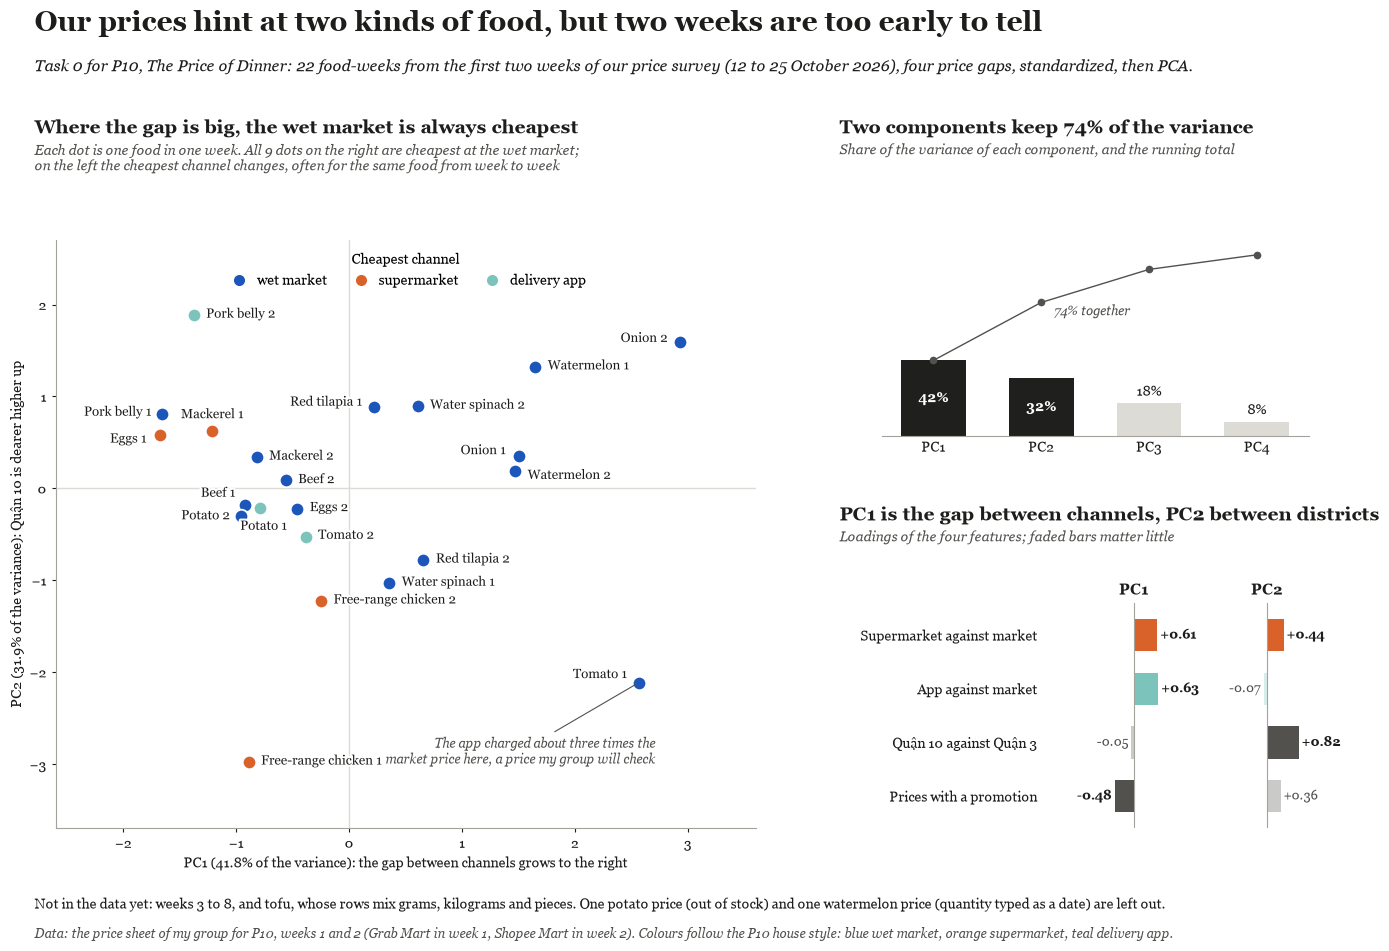

In [3]:
# Task 0: standardize the four features, run PCA, then draw the scree plot and the PC1 and PC2 map.
# The layout follows the Task 6 sheet at the top (SHEET_STYLE and PAPER come from that cell). The colours follow the
# house style of P10: each channel keeps its own colour, and grey marks what is not the point of a panel.
from matplotlib import patheffects
from matplotlib.lines import Line2D

Z0 = StandardScaler().fit_transform(p10[P10_FEATURES])
print("Means after standardizing:", np.round(Z0.mean(axis=0), 3))
print("Standard deviations:", np.round(Z0.std(axis=0), 3))
p10_pca = PCA().fit(Z0)
p10_scores = p10_pca.transform(Z0)
p10_var = p10_pca.explained_variance_ratio_ * 100
p10_cum = np.cumsum(p10_var)
p10[["PC1", "PC2"]] = p10_scores[:, :2]
p10_load = pd.DataFrame(p10_pca.components_[:2].T, index=P10_FEATURES, columns=["PC1", "PC2"])

# The cheapest channel of each food-week, from the average price of the two districts
channel_price = pd.DataFrame({ch: p10_raw[[f"{ch}_q10", f"{ch}_q3"]].mean(axis=1) for ch in ["market", "super", "app"]})
p10["cheapest"] = channel_price.idxmin(axis=1)

P10_CHANNEL = {"market": ("wet market", "#1d56ba"), "super": ("supermarket", "#d9622b"), "app": ("delivery app", "#7cc4bb")}
P10_INK, P10_CONTEXT, P10_TEXT, P10_NOTE = "#1f1f1d", "#dcdbd5", "#1d1d1b", "#52514e"
FEATURE_LOOK = {   # label and colour of each feature in the loadings panel
    "super_vs_market": ("Supermarket against market", P10_CHANNEL["super"][1]),
    "app_vs_market": ("App against market", P10_CHANNEL["app"][1]),
    "q10_vs_q3": ("Quận 10 against Quận 3", P10_NOTE),
    "promo_share": ("Prices with a promotion", P10_NOTE),
}
HALO = [patheffects.withStroke(linewidth=3, foreground=PAPER)]   # keeps labels readable on top of dots

with plt.rc_context(SHEET_STYLE):
    fig = plt.figure(figsize=(14, 9.8), facecolor=PAPER)
    map_ax = fig.add_axes([0.075, 0.13, 0.5, 0.6])
    scree_ax = fig.add_axes([0.665, 0.53, 0.305, 0.2])
    load_axes = [fig.add_axes([0.81, 0.13, 0.07, 0.23]), fig.add_axes([0.905, 0.13, 0.07, 0.23])]

    def panel_title(x, y, title, note):
        fig.text(x, y, title, ha="left", va="bottom", fontsize=13.5, fontweight="bold", color=P10_TEXT)
        fig.text(x, y - 0.006, note, ha="left", va="top", fontsize=10, style="italic", color=P10_NOTE)

    # 1. The PC1 and PC2 map: one dot per food and week, coloured by its cheapest channel
    map_ax.axhline(0, color=P10_CONTEXT, lw=1, zorder=0)
    map_ax.axvline(0, color=P10_CONTEXT, lw=1, zorder=0)
    for ch, (label, colour) in P10_CHANNEL.items():
        grp = p10[p10["cheapest"] == ch]
        map_ax.scatter(grp["PC1"], grp["PC2"], s=95, color=colour, edgecolor=PAPER, linewidth=1.3, zorder=3)
    # One label per dot, the food and its week; the crowded middle has hand-placed labels
    LABEL_SPOT = {  # (food, week): (offset x, offset y, alignment); every other dot gets its label on the right
        ("Pork belly", 1): (-9, 2, "right"), ("Eggs", 1): (-9, -3, "right"), ("Mackerel", 1): (0, 12, "center"),
        ("Beef", 1): (-7, 9, "right"), ("Da Lat potato", 2): (-9, 0, "right"), ("Da Lat potato", 1): (2, -13, "center"),
        ("Tomato", 1): (-9, 6, "right"), ("Red tilapia", 1): (-9, 4, "right"), ("Onion", 1): (-9, 4, "right"),
        ("Onion", 2): (-9, 3, "right"), ("Watermelon", 2): (9, -3, "left"),
    }
    SHORT_NAME = {"Da Lat potato": "Potato"}                         # short enough for the crowded middle
    for _, row in p10.iterrows():
        dx, dy, ha = LABEL_SPOT.get((row["food"], row["week"]), (9, 1, "left"))
        map_ax.annotate(f"{SHORT_NAME.get(row['food'], row['food'])} {row['week']}", (row["PC1"], row["PC2"]),
                        textcoords="offset points",
                        xytext=(dx, dy), ha=ha, va="center", fontsize=9.5, color=P10_TEXT, path_effects=HALO, zorder=4)
    tomato1 = p10[(p10["food"] == "Tomato") & (p10["week"] == 1)].iloc[0]
    map_ax.annotate("The app charged about three times the\nmarket price here, a price my group will check",
                    xy=(tomato1["PC1"], tomato1["PC2"]), xytext=(tomato1["PC1"] + 0.15, tomato1["PC2"] - 0.75),
                    ha="right", va="center", fontsize=9, style="italic", color=P10_NOTE, linespacing=1.3,
                    arrowprops=dict(arrowstyle="-", color=P10_NOTE, lw=0.8))
    handles = [Line2D([], [], marker="o", ls="", markersize=9, markerfacecolor=colour, markeredgecolor=PAPER, label=label)
               for label, colour in P10_CHANNEL.values()]
    map_ax.legend(handles=handles, title="Cheapest channel", loc="upper center", ncol=3, frameon=False, fontsize=10,
                  title_fontsize=10, handletextpad=0.3, columnspacing=1.4)
    map_ax.set_xlim(-2.6, 3.6)
    map_ax.set_ylim(-3.7, 2.7)
    map_ax.set_xlabel(f"PC1 ({p10_var[0]:.1f}% of the variance): the gap between channels grows to the right", fontsize=10,
                      color=P10_TEXT)
    map_ax.set_ylabel(f"PC2 ({p10_var[1]:.1f}% of the variance): Quận 10 is dearer higher up", fontsize=10, color=P10_TEXT)
    map_ax.spines[["top", "right"]].set_visible(False)
    map_ax.spines[["left", "bottom"]].set_color("#a3a29d")
    map_ax.tick_params(labelsize=10, length=3, colors=P10_TEXT)
    right = p10[p10["PC1"] > 0]
    panel_title(0.06, 0.835, ("Where the gap is big, the wet market is always cheapest" if (right["cheapest"] == "market").all()
                              else "Where the gap is big, the wet market is usually cheapest"),
                f"Each dot is one food in one week. All {len(right)} dots on the right are cheapest at the wet market;\n"
                "on the left the cheapest channel changes, often for the same food from week to week")

    # 2. Scree plot: PC1 and PC2 in ink, the other components in grey, the running total as a thin line
    x = np.arange(1, len(p10_var) + 1)
    scree_ax.bar(x, p10_var, width=0.6, color=[P10_INK if i <= 2 else P10_CONTEXT for i in x])
    for xi, v in zip(x, p10_var):                                  # inside the dark bars, above the grey ones
        kept = xi <= 2
        scree_ax.text(xi, v / 2 if kept else v + 2.5, f"{v:.0f}%", ha="center", va="center" if kept else "bottom",
                      fontsize=10, color=PAPER if kept else P10_TEXT, fontweight="bold" if kept else "normal")
    scree_ax.plot(x, p10_cum, color=P10_NOTE, lw=1, marker="o", markersize=4.5, zorder=3)
    scree_ax.text(2.12, p10_cum[1] - 1, f"{p10_cum[1]:.0f}% together", ha="left", va="top", fontsize=9, style="italic",
                  color=P10_NOTE)
    scree_ax.set_xticks(x, [f"PC{i}" for i in x])
    scree_ax.set_ylim(0, 108)
    scree_ax.set_yticks([])
    scree_ax.spines[["top", "right", "left"]].set_visible(False)
    scree_ax.spines["bottom"].set_color("#a3a29d")
    scree_ax.tick_params(axis="x", length=0, labelsize=10, colors=P10_TEXT)
    panel_title(0.635, 0.835, f"Two components keep {p10_cum[1]:.0f}% of the variance",
                "Share of the variance of each component, and the running total")

    # 3. Loadings: what each axis measures; faded bars matter little (size below 0.4)
    feats = list(P10_FEATURES)[::-1]
    for ax, pc in zip(load_axes, ["PC1", "PC2"]):
        for y, feat in enumerate(feats):
            v = p10_load.loc[feat, pc]
            strong = abs(v) >= 0.4
            ax.barh(y, v, height=0.6, color=FEATURE_LOOK[feat][1], alpha=1 if strong else 0.3)
            ax.text(v + (0.07 if v >= 0 else -0.07), y, f"{v:+.2f}", ha="left" if v >= 0 else "right", va="center",
                    fontsize=9.5, color=P10_TEXT if strong else P10_NOTE, fontweight="bold" if strong else "normal")
        ax.axvline(0, color="#a3a29d", lw=0.8)
        ax.set_xlim(-1.25, 1.25)
        ax.set_ylim(-0.6, len(feats) - 0.4)
        ax.set_xticks([])
        ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
        ax.set_title(pc, fontsize=11, fontweight="bold", color=P10_TEXT)
        ax.set_yticks(range(len(feats)), [FEATURE_LOOK[f][0] for f in feats] if pc == "PC1" else [])
        ax.tick_params(axis="y", length=0, labelsize=10, pad=34, colors=P10_TEXT)
    panel_title(0.635, 0.44, "PC1 is the gap between channels, PC2 between districts",
                "Loadings of the four features; faded bars matter little")

    # The verdict on top and the limits at the bottom
    fig.text(0.06, 0.965, "Our prices hint at two kinds of food, but two weeks are too early to tell",
             ha="left", va="top", fontsize=20, fontweight="bold", color=P10_TEXT)
    fig.text(0.06, 0.915, f"Task 0 for P10, The Price of Dinner: {len(p10)} food-weeks from the first two weeks of our price "
             "survey (12 to 25 October 2026), four price gaps, standardized, then PCA.",
             ha="left", va="top", fontsize=11.5, style="italic", color=P10_TEXT)
    fig.text(0.06, 0.045, "Not in the data yet: weeks 3 to 8, and tofu, whose rows mix grams, kilograms and pieces. One potato "
             "price (out of stock) and one watermelon price (quantity typed as a date) are left out.",
             ha="left", va="bottom", fontsize=10, color=P10_TEXT)
    fig.text(0.06, 0.015, "Data: the price sheet of my group for P10, weeks 1 and 2 (Grab Mart in week 1, Shopee Mart in week 2). "
             "Colours follow the P10 house style: blue wet market, orange supermarket, teal delivery app.",
             ha="left", va="bottom", fontsize=9, style="italic", color=P10_NOTE)
plt.show()

PC1 and PC2 keep 74% of the variance of the four features (42% and 32%). PC1 rises with the supermarket gap (loading 0.61) and the app gap (0.63) and falls with the promotion share (-0.48), so foods on the right cost much more outside the wet market. PC2 mostly follows the gap between Quận 10 and Quận 3 (0.82). All nine food-weeks on the right of the map are cheapest at the wet market, and most of them are vegetables and fruit, such as watermelon and onion. On the left, where the gaps are small, the cheapest channel changes: the wet market wins six times, the supermarket four times and the app three times, often for the same food in different weeks. Da Lat potato is the one vegetable on the left, and red tilapia is the one protein food on the right. The scatter hints at two groups, foods that are clearly cheaper at the wet market and foods with no clear winner, but in my group's opinion it is too early to tell. The 22 items come from only two weeks and 11 foods, and one point (tomato in week 1, where the app charged about three times the market price) may be a typing error that my group will check against the screenshot.

## Setup
Upload `gomart_stores_2025.csv` to the same folder as this notebook before you run it.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

GREY, LIGHT, DARK, BLUE, ORANGE = "#a3a29c", "#d9d8d3", "#52514e", "#2a78d6", "#eb6834"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]

## Task 1: Prepare

In [5]:
import pandas as pd
import numpy as np
from pathlib import Path

data_path = Path("data/raw/gomart_stores_2025.csv")

if not data_path.exists():
    data_path = Path("../../data/raw/gomart_stores_2025.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (140, 11)


,store_id,orders_per_day,avg_basket_k,median_delivery_min,ontime_share,ewallet_share,promo_order_share,evening_share,repeat_customer_share,items_per_order,zone
0,S001,142.0,189.0,22.1,65.0,41.0,30.0,68.0,66.0,10.7,Outer
1,S002,437.0,151.0,19.0,88.0,64.0,16.0,35.0,57.0,5.4,Central
2,S003,241.0,170.0,14.3,67.0,83.0,52.0,46.0,25.0,3.9,Outer
3,S004,167.0,129.0,22.5,78.0,80.0,27.0,40.0,40.0,5.7,Outer
4,S005,189.0,212.0,25.4,93.0,62.0,18.0,23.0,75.0,5.3,Outer


In [6]:
features = [
    "orders_per_day",
    "avg_basket_k",
    "median_delivery_min",
    "ontime_share",
    "ewallet_share",
    "promo_order_share",
    "evening_share",
    "repeat_customer_share",
    "items_per_order"
]

X = df[features].copy()

print("Feature matrix shape:", X.shape)
print("\nMissing values by feature:")
print(X.isna().sum())

Feature matrix shape: (140, 9)

Missing values by feature:
orders_per_day           0
avg_basket_k             0
median_delivery_min      0
ontime_share             0
ewallet_share            0
promo_order_share        0
evening_share            0
repeat_customer_share    0
items_per_order          0
dtype: int64


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized shape:", X_scaled.shape)
print("\nFeature means:")
print(np.round(X_scaled.mean(axis=0), 3))

print("\nFeature standard deviations:")
print(np.round(X_scaled.std(axis=0), 3))

Standardized shape: (140, 9)

Feature means:
[-0. -0.  0.  0. -0. -0.  0.  0.  0.]

Feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Task 1: Explanation
The item label is `store_id`. It only names each store and says nothing about how the store works, so my group keeps it out of the clustering.

The features are the nine numeric columns `orders_per_day`, `avg_basket_k`, `median_delivery_min`, `ontime_share`, `ewallet_share`, `promo_order_share`, `evening_share`, `repeat_customer_share` and `items_per_order`. Together they describe how busy a store is, how well it delivers and how its customers buy.

The context column is `zone` (Central, Inner or Outer). My group uses it only to describe the clusters afterwards and never to compute distances.

Without standardizing, `orders_per_day` would dominate every distance, because its standard deviation is about 89 orders while the shares vary by only 15 to 19 points, the delivery time by about 13 minutes and `items_per_order` by about 3 items, so a small gap in orders would outweigh a large gap in any other feature. Only `avg_basket_k` varies even more (about 119 thousand VND), so these two columns would decide the clusters almost alone. The cell above shows that after `StandardScaler` every feature has mean 0 and standard deviation 1, so all nine features count equally.

## Task 2: PCA

In [8]:
# Task 2.1: Fit PCA on the standardized data Z (X_scaled from Task 1), keeping all 9 components
pca = PCA(n_components=9)
scores = pca.fit_transform(X_scaled)

var_pct = pca.explained_variance_ratio_ * 100
cum_pct = np.cumsum(var_pct)

pc_table = pd.DataFrame({
    "component": [f"PC{i}" for i in range(1, 10)],
    "variance_%": var_pct.round(1),
    "cumulative_%": cum_pct.round(1),
})
display(pc_table)
print(f"PC1 + PC2 keep {cum_pct[1]:.1f}% of the variance")

,component,variance_%,cumulative_%
0,PC1,38.0,38.0
1,PC2,27.4,65.4
2,PC3,11.1,76.6
3,PC4,5.8,82.3
4,PC5,5.2,87.6
5,PC6,4.2,91.8
6,PC7,3.3,95.1
7,PC8,3.0,98.1
8,PC9,1.9,100.0


PC1 + PC2 keep 65.4% of the variance


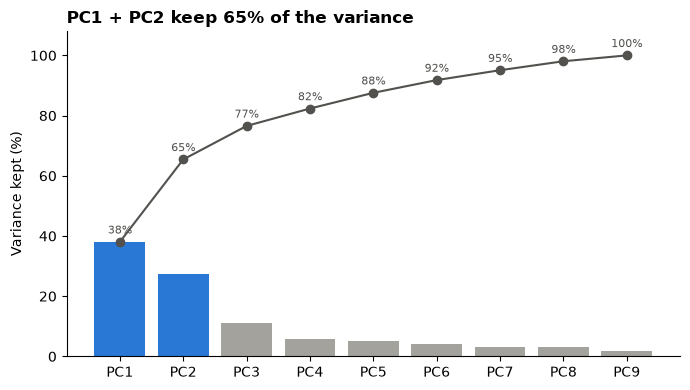

In [9]:
# Task 2.2: Scree plot: one bar per component plus the cumulative line
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(1, 10)
ax.bar(x, var_pct, color=GREY)
ax.bar([1, 2], var_pct[:2], color=BLUE)
ax.plot(x, cum_pct, color=DARK, marker="o", lw=1.5)
for xi, c in zip(x, cum_pct):
    ax.annotate(f"{c:.0f}%", (xi, c), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8, color=DARK)
ax.set_xticks(x)
ax.set_xticklabels([f"PC{i}" for i in x])
ax.set_ylim(0, 108)
ax.set_ylabel("Variance kept (%)")
ax.set_title(f"PC1 + PC2 keep {cum_pct[1]:.0f}% of the variance", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

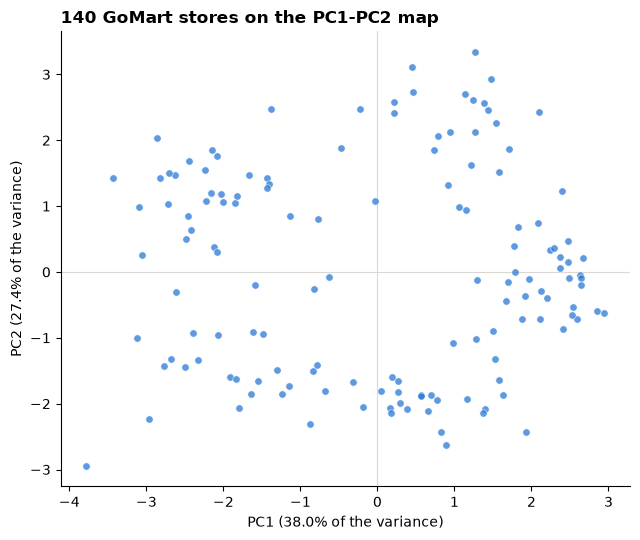

,PC1,PC2
evening_share,-0.40,0.13
median_delivery_min,-0.39,-0.17
items_per_order,-0.36,0.35
avg_basket_k,-0.18,0.49
promo_order_share,-0.17,-0.52
repeat_customer_share,0.15,0.55
orders_per_day,0.27,-0.06
ewallet_share,0.43,-0.03
ontime_share,0.47,0.13


In [10]:
# Task 2.3: PC1-PC2 map: one dot per store, variance % in both axis labels (no clustering yet)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(scores[:, 0], scores[:, 1], s=28, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.5)
ax.axhline(0, color=LIGHT, lw=0.8, zorder=0)
ax.axvline(0, color=LIGHT, lw=0.8, zorder=0)
ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}% of the variance)")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}% of the variance)")
ax.set_title("140 GoMart stores on the PC1-PC2 map", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# What drives each axis (loadings), to help read the map
loadings = pd.DataFrame(pca.components_[:2].T, index=features, columns=["PC1", "PC2"]).round(2)
display(loadings.sort_values("PC1"))

PC1 keeps 38.0% of the variance and PC2 keeps 27.4%, so the first two components keep 65.4% together. About one third of the variance stays in PC3 to PC9, so the map is a good picture of the stores but not a complete one.

PC1 rises with `ontime_share` (loading 0.47) and `ewallet_share` (0.43) and falls with `median_delivery_min` (-0.39) and `evening_share` (-0.40). Stores on the right deliver fast and on time and are often paid by e-wallet, while stores on the left are slower and get more evening orders. PC2 rises with `repeat_customer_share` (0.55) and `avg_basket_k` (0.49) and falls with `promo_order_share` (-0.52), so loyal stores with big baskets sit at the top and stores that rely on promotions sit at the bottom.

Before running any algorithm, my group thinks that there are four groups. The dots form a loose ring with an empty middle, and the ring has four dense areas: left, bottom, right and top. The borders between these areas are blurry, so four is a guess that my group tests in Task 3, not a result.

## Task 3: Choose k

In [11]:
# Task 3.1: compare k = 2 to 8 on the standardized data
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Find the dataset from the current working directory
data_path = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate = folder / "data" / "raw" / "gomart_stores_2025.csv"
    if candidate.is_file():
        data_path = candidate
        break

if data_path is None:
    raise FileNotFoundError(
        "Cannot find data/raw/gomart_stores_2025.csv. "
        "Check the project folder."
    )

df = pd.read_csv(data_path)

features = [
    "orders_per_day",
    "avg_basket_k",
    "median_delivery_min",
    "ontime_share",
    "ewallet_share",
    "promo_order_share",
    "evening_share",
    "repeat_customer_share",
    "items_per_order"
]

X = df[features].copy()

if X.isna().any().any():
    raise ValueError(
        "The data has missing values. Check Task 1 again."
    )

# Standardize before fitting KMeans
X_scaled = StandardScaler().fit_transform(X)
Z = X_scaled

ks = list(range(2, 9))
inertia = []
sil = []

for k in ks:
    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=0
    ).fit(Z)

    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_))

k_results = pd.DataFrame({
    "k": ks,
    "inertia": inertia,
    "silhouette": sil
})

print(
    k_results.round({
        "inertia": 1,
        "silhouette": 3
    }).to_string(index=False)
)

 k  inertia  silhouette
 2    871.3       0.288
 3    674.0       0.295
 4    523.4       0.304
 5    420.2       0.324
 6    393.3       0.302
 7    373.8       0.260
 8    355.9       0.236


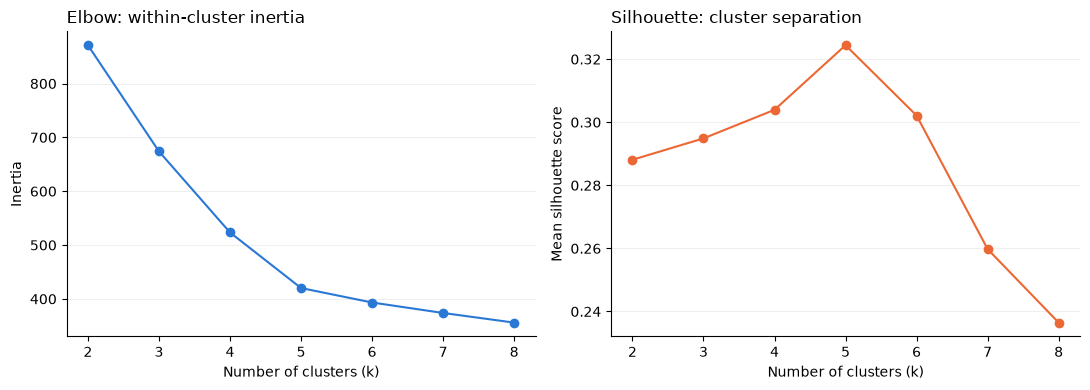

Selected number of clusters: k = 5


In [12]:
# Task 3.2: elbow and silhouette charts
import matplotlib.pyplot as plt

BLUE = "#2a78d6"
ORANGE = "#eb6834"

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Elbow
axes[0].plot(
    k_results["k"],
    k_results["inertia"],
    marker="o",
    color=BLUE
)
axes[0].set_title("Elbow: within-cluster inertia", loc="left")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

# Silhouette
axes[1].plot(
    k_results["k"],
    k_results["silhouette"],
    marker="o",
    color=ORANGE
)
axes[1].set_title("Silhouette: cluster separation", loc="left")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Mean silhouette score")

for ax in axes:
    ax.set_xticks(k_results["k"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

# My group chooses k after reading both the elbow and the silhouette chart
chosen_k = 5
print(f"Selected number of clusters: k = {chosen_k}")

My group chooses k = 5. The elbow chart shows that the inertia falls steeply from k = 2 (871) to k = 5 (420) and only slowly after that (393 at k = 6 and 356 at k = 8), so the bend of the elbow is at k = 5. The silhouette chart agrees, because its highest value is 0.324 at k = 5, about 0.02 above k = 4 (0.304) and k = 6 (0.302).

In Task 2 my group guessed four groups from the map, but both charts point to five, so my group follows the charts. A silhouette of 0.324 is only moderate, so Task 5 checks whether the five groups are real.

## Task 4: Cluster, profile and name

In [13]:
# Fit KMeans and deterministically map clusters to A, B, C, D, E by orders_per_day descending
from sklearn.cluster import KMeans

# 1. Fit KMeans with k = 5
km5 = KMeans(n_clusters=5, n_init=10, random_state=0)
raw_labels = km5.fit_predict(X_scaled)
df["cluster_raw"] = raw_labels

# 2. Sort clusters by mean orders_per_day descending to ensure deterministic labeling
ordered_clusters = df.groupby("cluster_raw")["orders_per_day"].mean().sort_values(ascending=False).index
letters = ["A", "B", "C", "D", "E"]
cluster_map = {orig: letter for letter, orig in zip(letters, ordered_clusters)}

# 3. Assign letter labels
df["cluster"] = df["cluster_raw"].map(cluster_map)

# 4. Display mapping and summary statistics
print("Cluster mapping (sorted by orders_per_day descending):")
for letter in letters:
    orig = [k for k, v in cluster_map.items() if v == letter][0]
    mean_ord = df[df["cluster"] == letter]["orders_per_day"].mean()
    cnt = (df["cluster"] == letter).sum()
    print(f"  Cluster {letter} (Original {orig}): {cnt} stores | Mean orders/day = {mean_ord:.1f}")

# 5. Geographic zone distribution (context only)
print("\nCluster distribution by zone:")
display(pd.crosstab(df["cluster"], df["zone"], margins=True).loc[letters + ["All"]])

Cluster mapping (sorted by orders_per_day descending):
  Cluster A (Original 1): 25 stores | Mean orders/day = 235.8
  Cluster B (Original 3): 34 stores | Mean orders/day = 232.7
  Cluster C (Original 0): 32 stores | Mean orders/day = 166.3
  Cluster D (Original 2): 23 stores | Mean orders/day = 117.8
  Cluster E (Original 4): 26 stores | Mean orders/day = 56.0

Cluster distribution by zone:


zone,Central,Inner,Outer,All
cluster,,,,
A,5,14,6,25
B,21,11,2,34
C,3,13,16,32
D,14,7,2,23
E,6,9,11,26
All,49,54,37,140


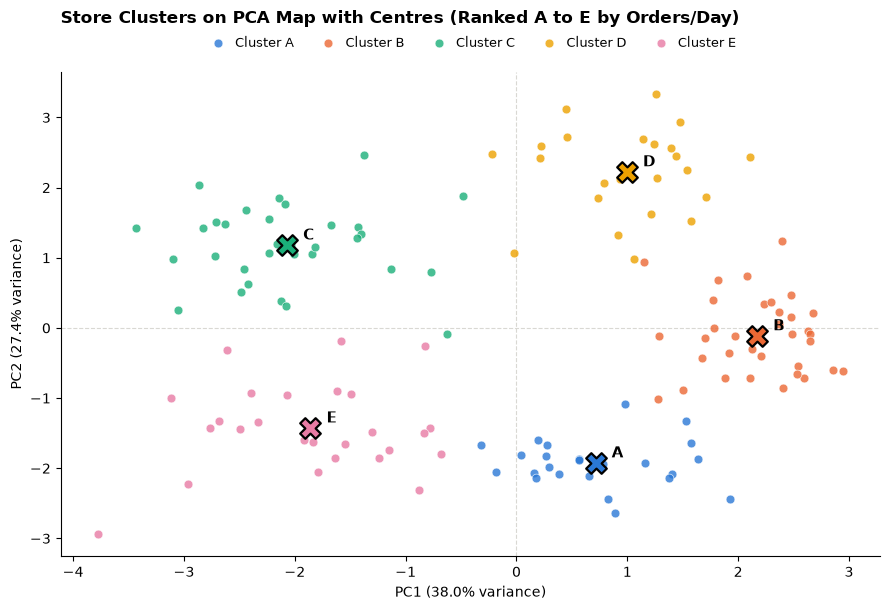

In [14]:
# Draw the clusters A to E on the PCA map with their centres
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
scores = pca.fit_transform(X_scaled)
df["PC1"] = scores[:, 0]
df["PC2"] = scores[:, 1]

centroids_pc = df.groupby("cluster")[["PC1", "PC2"]].mean()


CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
letters = ["A", "B", "C", "D", "E"]
cluster_labels = [f"Cluster {l}" for l in letters]

fig, ax = plt.subplots(figsize=(9, 6.2))

for idx, letter in enumerate(letters):
    subset = df[df["cluster"] == letter]
    ax.scatter(subset["PC1"], subset["PC2"],
               color=CAT[idx], label=cluster_labels[idx],
               s=40, alpha=0.8, edgecolor="white", linewidth=0.5)


for idx, letter in enumerate(letters):
    cx, cy = centroids_pc.loc[letter, "PC1"], centroids_pc.loc[letter, "PC2"]
    ax.scatter(cx, cy, color=CAT[idx], s=220, marker="X", 
               edgecolor="black", linewidth=1.6, zorder=5)
    ax.annotate(f" {letter}", (cx, cy), textcoords="offset points", xytext=(8, 4),
                fontweight="bold", fontsize=11, color="black")

ax.axhline(0, color="#d9d8d3", lw=0.8, ls="--", zorder=0)
ax.axvline(0, color="#d9d8d3", lw=0.8, ls="--", zorder=0)

ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}% variance)")
ax.set_title("Store Clusters on PCA Map with Centres (Ranked A to E by Orders/Day)", 
             loc="left", fontweight="bold", fontsize=12, pad=35)

ax.legend(bbox_to_anchor=(0.5, 1.02), loc="lower center", ncol=5,
          frameon=False, fontsize=9.5, handletextpad=0.3, columnspacing=1.6)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

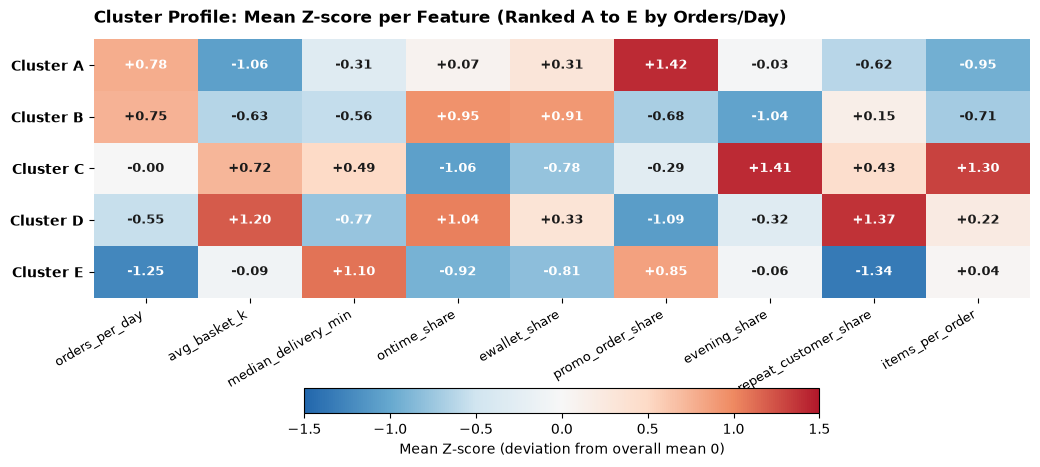

In [15]:
# Profile heatmap: Colorblind-safe Blue-White-Red diverging palette (Cluster A to E)
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

letters = ["A", "B", "C", "D", "E"]
profile_z = pd.DataFrame(X_scaled, columns=features).groupby(df["cluster"]).mean().loc[letters]

safe_colors = ["#2166ac", "#67a9cf", "#d1e5f0", "#f7f7f7", "#fddbc7", "#ef8a62", "#b2182b"]
safe_cmap = LinearSegmentedColormap.from_list("safe_rdbu", safe_colors)

norm = TwoSlopeNorm(vmin=-1.5, vcenter=0, vmax=1.5)

fig, ax = plt.subplots(figsize=(10.5, 4.8))
cax = ax.imshow(profile_z.values, cmap=safe_cmap, norm=norm, aspect="auto")

for i in range(profile_z.shape[0]):
    for j in range(profile_z.shape[1]):
        val = profile_z.iloc[i, j]

        text_color = "white" if abs(val) >= 0.75 else "#1a1a1a"
        ax.text(j, i, f"{val:+.2f}", ha="center", va="center",
                color=text_color, fontsize=9.5, fontweight="bold")

ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=30, ha="right", fontsize=9.5)
ax.set_yticks(range(5))
ax.set_yticklabels([f"Cluster {ltr}" for ltr in letters], fontsize=10, fontweight="bold")
ax.set_title("Cluster Profile: Mean Z-score per Feature (Ranked A to E by Orders/Day)", 
             loc="left", fontweight="bold", fontsize=12, pad=12)

cbar = fig.colorbar(cax, ax=ax, orientation="horizontal", pad=0.22, shrink=0.55)
cbar.set_label("Mean Z-score (deviation from overall mean 0)")

ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

My group gives each cluster a name that describes its behaviour. The table lists the profile cells behind each name, written as the z-score with the real average in brackets.

| Cluster | Name | Profile cells that justify the name |
|:---:|---|---|
| **A** | **High-volume discount small basket stores** | `orders_per_day` +0.78 (235.8 orders), `promo_order_share` +1.42 (56.8%), `avg_basket_k` -1.06 (115.6 thousand VND). These stores get the most orders, about as many as type B, and more than half of their orders use a promotion. Their baskets are the smallest of all types. |
| **B** | **Daytime digital grab-and-go stores** | `evening_share` -1.04 (20.9%), `ewallet_share` +0.91 (68.7%), `ontime_share` +0.95 (87.3%), `median_delivery_min` -0.56 (24.3 minutes). Only about one in five orders comes between 18:00 and 21:00, most customers pay by e-wallet, and deliveries are fast and on time. |
| **C** | **Evening large-basket grocery stores** | `evening_share` +1.41 (63.5%), `items_per_order` +1.30 (12.3 items), `ontime_share` -1.06 (54.3%). Almost two thirds of the orders come between 18:00 and 21:00, the orders have many items, and only about half of them arrive on time. The data does not show whether the evening orders or the large orders cause the delays. |
| **D** | **Loyal premium fast-delivery stores** | `repeat_customer_share` +1.37 (76.0%), `avg_basket_k` +1.20 (385.3 thousand VND), `median_delivery_min` -0.77 (21.6 minutes). These stores have the most returning customers, the largest baskets and the fastest deliveries. They also use the fewest promotions (`promo_order_share` -1.09). |
| **E** | **Slow-delivery low-traffic promo stores** | `orders_per_day` -1.25 (56.0 orders), `median_delivery_min` +1.10 (45.0 minutes), `repeat_customer_share` -1.34 (29.3%). These stores get the fewest orders, deliver the slowest and have the fewest returning customers. They also use many promotions (`promo_order_share` +0.85), but this does not prove that promotions drive customers away. |

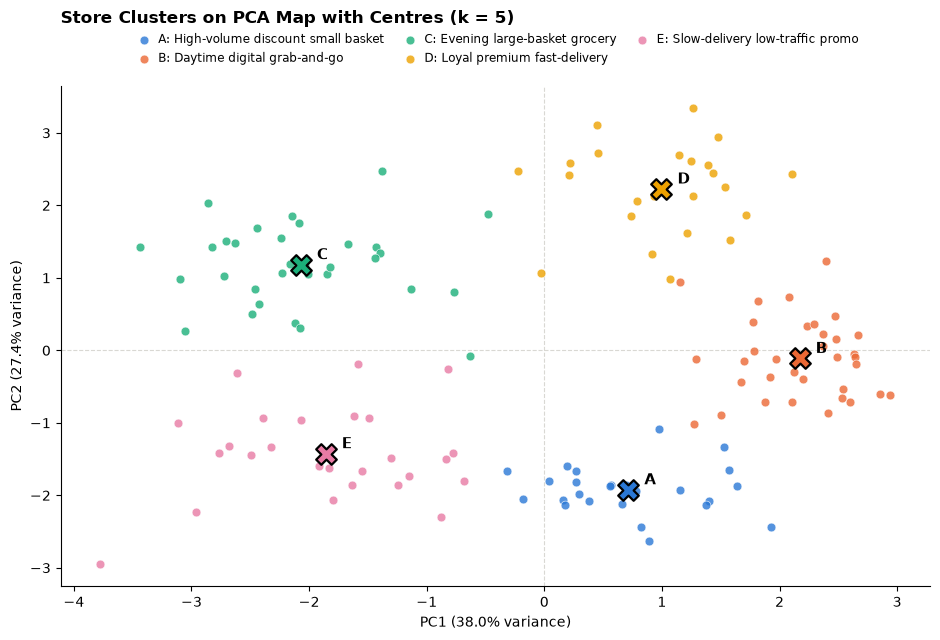

In [16]:
pca = PCA(n_components=2)
scores = pca.fit_transform(X_scaled)
df["PC1"] = scores[:, 0]
df["PC2"] = scores[:, 1]

centroids_pc = df.groupby("cluster")[["PC1", "PC2"]].mean()

CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
letters = ["A", "B", "C", "D", "E"]
cluster_names = [
    "A: High-volume discount small basket",
    "B: Daytime digital grab-and-go",
    "C: Evening large-basket grocery",
    "D: Loyal premium fast-delivery",
    "E: Slow-delivery low-traffic promo"
]

fig, ax = plt.subplots(figsize=(9.5, 6.5))


for idx, letter in enumerate(letters):
    subset = df[df["cluster"] == letter]
    ax.scatter(subset["PC1"], subset["PC2"],
               color=CAT[idx], label=cluster_names[idx],
               s=40, alpha=0.8, edgecolor="white", linewidth=0.5)

for idx, letter in enumerate(letters):
    cx, cy = centroids_pc.loc[letter, "PC1"], centroids_pc.loc[letter, "PC2"]
    ax.scatter(cx, cy, color=CAT[idx], s=220, marker="X", 
               edgecolor="black", linewidth=1.6, zorder=5)
    ax.annotate(f" {letter}", (cx, cy), textcoords="offset points", xytext=(8, 4),
                fontweight="bold", fontsize=11, color="black")


ax.axhline(0, color="#d9d8d3", lw=0.8, ls="--", zorder=0)
ax.axvline(0, color="#d9d8d3", lw=0.8, ls="--", zorder=0)

ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}% variance)")
ax.set_title("Store Clusters on PCA Map with Centres (k = 5)", 
             loc="left", fontweight="bold", fontsize=12, pad=45)

ax.legend(bbox_to_anchor=(0.5, 1.02), loc="lower center", ncol=3,
          frameon=False, fontsize=8.5, handletextpad=0.2, columnspacing=1.2)

ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Task 5: Are the groups real?
### 5.1 Different seeds and a different method (Ward)

In [17]:
# Task 5.1: check that k-means gives the same groups with different random seeds
K = 5
Z = X_scaled

# 1. Run KMeans with 3 different random seeds
seeds = [0, 1, 2]
labs = [KMeans(n_clusters=K, n_init=10, random_state=s).fit(Z).labels_ for s in seeds]

print("Task 5.1: k-means with three different seeds")
print(f"ARI (seed 0 vs 1): {adjusted_rand_score(labs[0], labs[1]):.3f}")
print(f"ARI (seed 0 vs 2): {adjusted_rand_score(labs[0], labs[2]):.3f}")
print(f"ARI (seed 1 vs 2): {adjusted_rand_score(labs[1], labs[2]):.3f}")



Task 5.1: k-means with three different seeds
ARI (seed 0 vs 1): 1.000
ARI (seed 0 vs 2): 1.000
ARI (seed 1 vs 2): 1.000


In [18]:
# Compare with Ward hierarchical clustering
from scipy.cluster.hierarchy import linkage, fcluster

print("\nTask 5.1: k-means against Ward hierarchical clustering")
L = linkage(Z, method="ward")
ward = fcluster(L, K, criterion="maxclust")
df["ward"] = ward

# Cross-tabulation between K-Means (A-E) and Ward (1-5)
letters = ["A", "B", "C", "D", "E"]
ct = pd.crosstab(df["cluster"], df["ward"], rownames=["k-means"], colnames=["Ward"]).loc[letters]
print("Cross-tabulation (k-means vs Ward):")
display(ct)

ari_ward = adjusted_rand_score(df["cluster"], ward)
print(f"Adjusted Rand Index (k-means vs Ward): {ari_ward:.3f}")

# Identify stores classified differently
# 'home' maps each k-means cluster to its dominant Ward group
home = ct.idxmax(axis=1)
print("\nDominant Ward group for each k-means cluster:")
for ltr, h in home.items():
    print(f"  Cluster {ltr} -> Ward {h}")

moved_mask = df["ward"] != df["cluster"].map(home).values
moved = df.loc[moved_mask, ["store_id", "cluster", "ward", "zone"]]

print(f"\nStores classified differently ({len(moved)}/140 stores, {len(moved)/len(df)*100:.1f}%):")
display(moved)


Task 5.1: k-means against Ward hierarchical clustering
Cross-tabulation (k-means vs Ward):


Ward,1,2,3,4,5
k-means,,,,,
A,0,0,0,25,0
B,0,0,1,0,33
C,30,2,0,0,0
D,1,0,22,0,0
E,0,26,0,0,0


Adjusted Rand Index (k-means vs Ward): 0.929

Dominant Ward group for each k-means cluster:
  Cluster A -> Ward 4
  Cluster B -> Ward 5
  Cluster C -> Ward 1
  Cluster D -> Ward 3
  Cluster E -> Ward 2

Stores classified differently (4/140 stores, 2.9%):


,store_id,cluster,ward,zone
18,S019,D,1,Outer
56,S057,C,2,Outer
61,S062,C,2,Outer
78,S079,B,3,Inner


### 5.2 A null baseline (shuffle each column)

In [19]:
# Task 5.2: null baseline, made by shuffling each feature on its own

# Silhouette score of the real clustering
real_silhouette = silhouette_score(Z, df["cluster_raw"])

print(f"Real silhouette score: {real_silhouette:.3f}")

Real silhouette score: 0.324


In [20]:
# Create null datasets by independently shuffling each feature

rng = np.random.default_rng(42)
n_repeats = 20
null_silhouettes = []

for i in range(n_repeats):
    # Make a copy of the standardized data
    Z_null = Z.copy()

    # Shuffle each feature independently
    for j in range(Z_null.shape[1]):
        Z_null[:, j] = rng.permutation(Z_null[:, j])

    # Run KMeans with the same k = 5
    km_null = KMeans(n_clusters=K, n_init=10, random_state=i)
    null_labels = km_null.fit_predict(Z_null)

    # Calculate silhouette score
    null_score = silhouette_score(Z_null, null_labels)
    null_silhouettes.append(null_score)

null_silhouettes = np.array(null_silhouettes)

print(f"Real silhouette: {real_silhouette:.3f}")
print(f"Null mean: {null_silhouettes.mean():.3f}")
print(f"Null range: {null_silhouettes.min():.3f} to {null_silhouettes.max():.3f}")
print(f"Null runs >= real: {(null_silhouettes >= real_silhouette).sum()}/{n_repeats}")

Real silhouette: 0.324
Null mean: 0.105
Null range: 0.088 to 0.125
Null runs >= real: 0/20


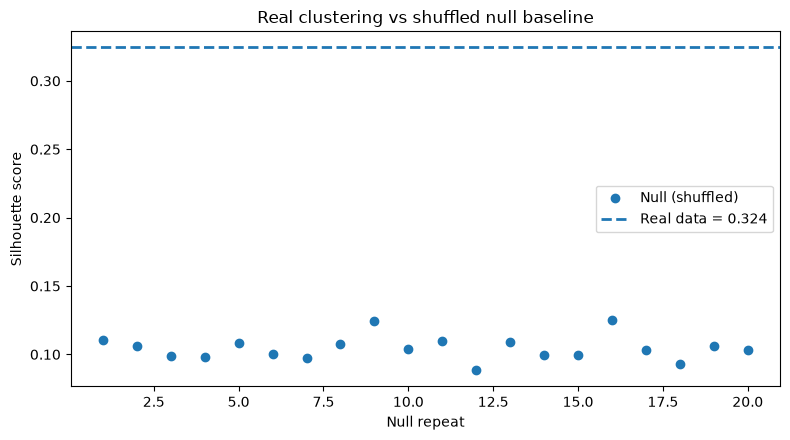

In [21]:
# Visual comparison: real silhouette vs null baseline

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.scatter(
    range(1, n_repeats + 1),
    null_silhouettes,
    label="Null (shuffled)"
)

ax.axhline(
    real_silhouette,
    linestyle="--",
    linewidth=2,
    label=f"Real data = {real_silhouette:.3f}"
)

ax.set_xlabel("Null repeat")
ax.set_ylabel("Silhouette score")
ax.set_title("Real clustering vs shuffled null baseline")
ax.legend()

plt.tight_layout()
plt.show()

My group compares the real clustering with 20 null datasets. In each null dataset every feature column is shuffled on its own, which keeps the spread of each column but breaks the links between the columns. The real clustering has a silhouette of 0.324. The 20 null runs have an average silhouette of 0.105 and range from 0.088 to 0.125, so none of them reaches the real value (0 of 20). The five groups are therefore much clearer than the groups that k-means finds in data without real structure.

In [22]:
# Inspect standardized profiles of stores where KMeans and Ward disagree

moved_ids = moved["store_id"].tolist()

moved_profiles = pd.DataFrame(
    Z,
    columns=features,
    index=df["store_id"]
)

display(moved_profiles.loc[moved_ids].round(2))

,orders_per_day,avg_basket_k,median_delivery_min,ontime_share,ewallet_share,promo_order_share,evening_share,repeat_customer_share,items_per_order
store_id,,,,,,,,,
S019,-0.39,0.22,-0.42,-0.41,0.26,-0.57,0.69,1.08,-0.15
S057,-0.79,0.59,1.60,-0.72,-0.67,-0.36,1.26,-0.14,0.13
S062,-0.29,1.63,1.73,-0.17,-1.00,-0.36,0.69,0.03,0.69
S079,0.38,0.17,1.13,1.11,0.86,-1.38,-0.63,0.67,-0.15


Only 4 of the 140 stores (2.9%) land in different groups under k-means and Ward. Their profiles mix the features of two groups. S019 has many repeat customers and many evening orders. S057 has many evening orders but few orders in total and slow delivery. S062 has large baskets and many evening orders, but very slow delivery and little e-wallet use. S079 delivers on time, has high e-wallet use and uses very few promotions. These stores sit between two groups, and this is the likely reason why the two methods place them differently.

### Final verdict
In my group's opinion, the five groups are real, with one note of caution. K-means gives exactly the same groups with three different seeds (adjusted Rand index 1.000), so the result does not depend on the random start. Ward clustering agrees closely with k-means (adjusted Rand index 0.929), and only 4 of the 140 stores move, all of them stores that sit between two groups. The real silhouette of 0.324 is about three times the null average of 0.105, and none of the 20 shuffled datasets comes close to it. The note of caution is that a silhouette of 0.324 is modest, so the groups overlap at their edges and a few stores could belong to either of two groups.

## Task 6: The one-page chart
My group chooses one finding: the evening large-basket stores (type C) take 23% of all orders but make 41% of all late deliveries, about 2,430 of the 5,910 late deliveries a day. The chart follows the decision sheet from our week 1 work, so each of its four panels answers a different question with the chart type that fits it. The bar chart shows where the late deliveries come from. The dot plot shows that all 32 type C stores are on time less often than the average store, so the problem belongs to the whole type and not to a few stores. The scatter plot shows that stores with more evening orders deliver fewer orders on time, and its arrow shows what the network would gain if type C stores were on time as often as the other stores: about 1,400 fewer late deliveries a day. The table shows that type C stores are as busy as the other stores but get twice as many evening orders and bigger orders. The same chart sits under the memo at the top.

A delivery is late when it takes more than 35 minutes, and `ontime_share` is the share of orders that arrive within 35 minutes. My group therefore estimates the late deliveries of a store per day as `orders_per_day * (1 - ontime_share / 100)` and adds them up for each type. This is an estimate from yearly averages, not a count of real orders.

The chart shows where and when the late deliveries happen, not why they happen. Type C stores get the most evening orders and the orders with the most items, but this data cannot tell whether either of these causes the delays. That is why the memo suggests a small test with extra evening riders instead of a change for all stores.

,stores,orders_per_day,late_per_day,evening_per_day,orders_%,late_%,late_rate_%,evening_rate_%
cluster,,,,,,,,
C,32,5321.0,2430.4,3347.0,22.8,41.1,45.7,62.9
A,25,5894.0,1593.7,2297.4,25.3,27.0,27.0,39.0
B,34,7913.0,955.4,1716.5,34.0,16.2,12.1,21.7
E,26,1456.0,648.8,552.7,6.3,11.0,44.6,38.0
D,23,2709.0,279.8,922.4,11.6,4.7,10.3,34.0


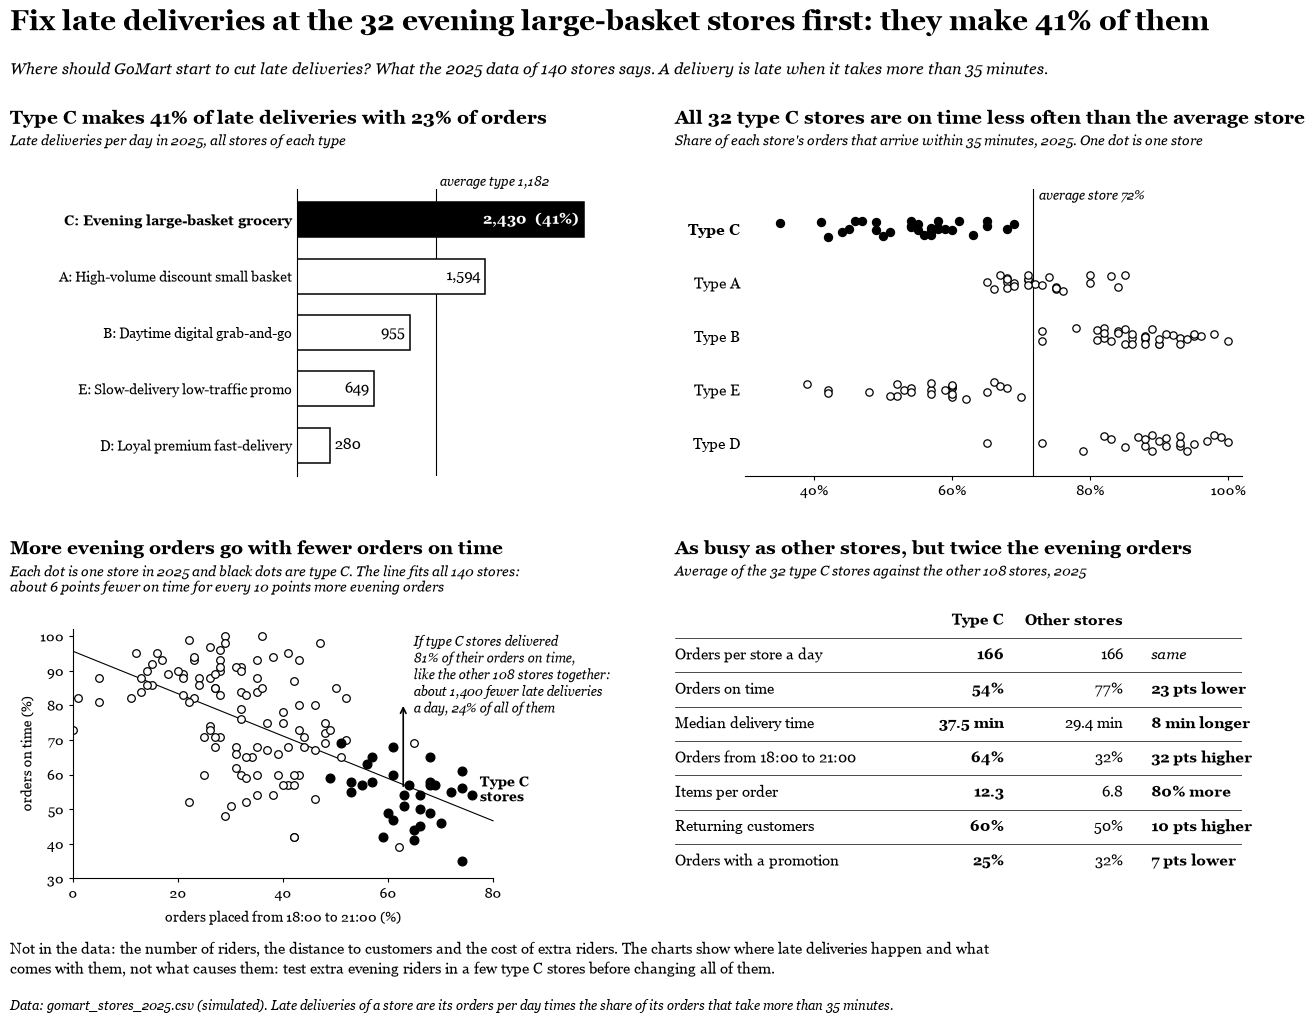

In [23]:
# Task 6: the memo chart, drawn again from the Task 4 clusters (df["cluster"])
assert (df["cluster"].values == memo_df["cluster"].values).all(), "the memo chart must use the Task 4 clusters"

display(store_type_table(df).round(1))
plot_one_page(df)
plt.show()

## Task 7: Team and AI
| Member | What they did |
|---|---|
| Nguyễn Minh Nguyệt | Task 1: loaded the data, named the label, the features and the context column, standardized the features and checked that each has mean 0 and standard deviation 1 (pull request #1, 21/10) |
| Phạm Tuấn Anh | Task 2: fitted PCA, drew the scree plot and the PC1 and PC2 map with the loadings, and guessed the number of groups before clustering (pull request #2, 22/10) |
| Phạm Quang Minh | Task 3: ran k-means for k = 2 to 8, drew the elbow and silhouette charts and chose k = 5 (pull request #3, 22/10) |
| Trần Nguyễn Thanh Thảo | Task 4: fitted k-means with k = 5, drew the clusters on the PCA map and the z-score heatmap, and named the five clusters. Task 5.1: compared three seeds and Ward clustering (24/10, part of pull request #4) |
| Trần Nhã Đoan | Task 5.2: ran the null baseline with 20 shuffles, checked the 4 stores that move between k-means and Ward, and wrote the final verdict (pull request #4, 25/10) |
| Nguyễn Hoàng Minh (leader) | Task 0 with the first two weeks of our P10 price survey, the Task 6 chart and memo, Task 7, and the review and merge of every pull request into `dev` |

In [5]:
AI_USE = """Home Work 4
Tools used:
Claude Code (made by Anthropic), used by my group.

What we asked:
We asked Claude Code to review pull requests #1 to #4. It ran the notebook from top to bottom and checked
that every printed number and every number in our text matched the output.
We asked it to suggest one finding for Task 6 and to draft the Task 6 chart code, the Big Idea, the memo
and this Task 7 table from our git history.
We asked it to rewrite the text of the notebook in plain English with clear sentences.
We asked it to turn the first two weeks of our P10 price sheet into the Task 0 sample, to suggest
the item and the four features, and to draft the Task 0 code and text.
We did not ask Claude Code to choose k or to name the clusters. The value k = 5 (Task 3) and the five
names (Task 4) were already in the notebook before the review.
"""

print(AI_USE)

Home Work 4
Tools used:
Claude Code (made by Anthropic), used by my group.

What we asked:
We asked Claude Code to review pull requests #1 to #4. It ran the notebook from top to bottom and checked
that every printed number and every number in our text matched the output.
We asked it to suggest one finding for Task 6 and to draft the Task 6 chart code, the Big Idea, the memo
and this Task 7 table from our git history.
We asked it to rewrite the text of the notebook in plain English with clear sentences.
We asked it to turn the first two weeks of our P10 price sheet into the Task 0 sample, to suggest
the item and the four features, and to draft the Task 0 code and text.
We did not ask Claude Code to choose k or to name the clusters. The value k = 5 (Task 3) and the five
names (Task 4) were already in the notebook before the review.

